<a href="https://colab.research.google.com/github/Eccys/dsrp/blob/main/student_academic_success.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# University Student Academic Success
why some drop out and some graduate?

## Setup stuff

In [ ]:
# importing everything we need
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# make it so the tables show all the columns and not cut them off
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)

# this makes the graphs show up in the notebook
%matplotlib inline
print("done importing!")


done importing!


## Loading the data
getting the csv from github

In [ ]:
# this is the link to the dataset on github
url = "https://raw.githubusercontent.com/frontiertechinstitute/datasets/main/University%20Student%20Academic%20Success%20Dataset/university_student_academic_success_dataset.csv"

# read the csv file into a dataframe
# the separator is a semicolon not a comma which is kinda weird
df = pd.read_csv(url, sep=";", encoding="utf-8-sig")

# clean up the column names just in case theres extra spaces
df.columns = df.columns.str.strip()

# lets see how big the dataset is
print("Number of rows:", len(df))
print("Number of columns:", len(df.columns))
print()
print("Here are all the columns:")
for col in df.columns:
    print(" -", col)

print()
# show the first few rows
df.head()


Number of rows: 4424
Number of columns: 37

Here are all the columns:
 - Marital status
 - Application mode
 - Application order
 - Course
 - Daytime/evening attendance
 - Previous qualification
 - Previous qualification (grade)
 - Nacionality
 - Mother's qualification
 - Father's qualification
 - Mother's occupation
 - Father's occupation
 - Admission grade
 - Displaced
 - Educational special needs
 - Debtor
 - Tuition fees up to date
 - Gender
 - Scholarship holder
 - Age at enrollment
 - International
 - Curricular units 1st sem (credited)
 - Curricular units 1st sem (enrolled)
 - Curricular units 1st sem (evaluations)
 - Curricular units 1st sem (approved)
 - Curricular units 1st sem (grade)
 - Curricular units 1st sem (without evaluations)
 - Curricular units 2nd sem (credited)
 - Curricular units 2nd sem (enrolled)
 - Curricular units 2nd sem (evaluations)
 - Curricular units 2nd sem (approved)
 - Curricular units 2nd sem (grade)
 - Curricular units 2nd sem (without evaluations)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


## Checking the data
making sure theres no missing stuff or duplicates

In [ ]:
# how many rows and columns do we have
num_rows = len(df)
num_cols = len(df.columns)
print("rows:", num_rows)
print("columns:", num_cols)

# check for missing values
print()
print("checking for missing values...")
missing = df.isna().sum()
has_missing = False
for col in df.columns:
    if missing[col] > 0:
        print("  ", col, "is missing", missing[col], "values")
        has_missing = True
if has_missing == False:
    print("  no missing values! nice")

# check for duplicate rows
print()
num_dupes = df.duplicated().sum()
print("duplicate rows:", num_dupes)

# see how many students are in each category
print()
print("how many students in each target group:")
print(df["Target"].value_counts())

# also show the percentages
print()
print("percentages:")
counts = df["Target"].value_counts()
total = len(df)
for target_name in counts.index:
    pct = round(counts[target_name] / total * 100, 1)
    print("  ", target_name, "->", pct, "%")


rows: 4424
columns: 37

checking for missing values...
  no missing values! nice

duplicate rows: 0

how many students in each target group:
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

percentages:
   Graduate -> 49.9 %
   Dropout -> 32.1 %
   Enrolled -> 17.9 %


In [ ]:
# the scholarship column is just 0 and 1 which is confusing
# so im gonna make new columns with actual words

# 1 means they have a scholarship, 0 means they dont
df["scholarship_label"] = df["Scholarship holder"].map({1: "Scholarship", 0: "No scholarship"})

# 1 means daytime, 0 means evening
df["attendance_label"] = df["Daytime/evening attendance"].map({1: "Daytime", 0: "Evening"})

print("ok added the label columns")
print("scholarship labels:", df["scholarship_label"].unique())
print("attendance labels:", df["attendance_label"].unique())


ok added the label columns
scholarship labels: ['No scholarship' 'Scholarship']
attendance labels: ['Daytime' 'Evening']


## Scholarships vs outcome
lets see if having a scholarship changes whether students graduate or drop out

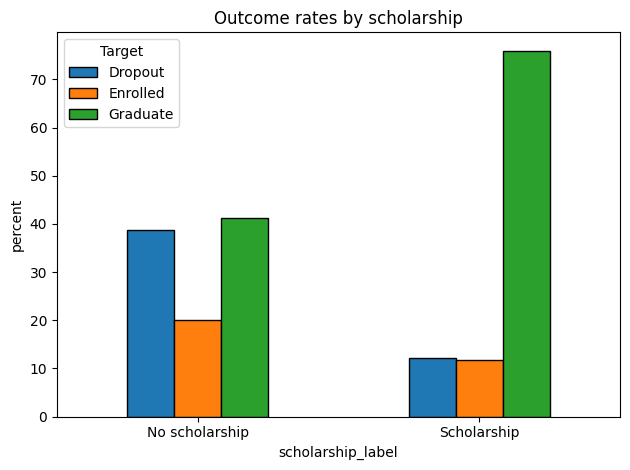

here are the actual percentages:
Target             Dropout  Enrolled  Graduate
scholarship_label                             
No scholarship        38.7      20.0      41.3
Scholarship           12.2      11.8      76.0


In [ ]:
# make a crosstab to compare scholarship vs target
ct = pd.crosstab(df["scholarship_label"], df["Target"], normalize="index") * 100

# put the columns in an order that makes sense
ct = ct[["Dropout", "Enrolled", "Graduate"]]

# make a bar chart
ct.plot(kind="bar", stacked=False, edgecolor="black")
plt.title("Outcome rates by scholarship")
plt.ylabel("percent")
plt.xticks(rotation=0)
plt.legend(title="Target")
plt.tight_layout()
plt.show()

# also print the numbers
print("here are the actual percentages:")
print(ct.round(1))


## Age stuff
looking at how old the students are

age stats:
count    4424.000000
mean       23.265145
std         7.587816
min        17.000000
25%        19.000000
50%        20.000000
75%        25.000000
max        70.000000
Name: Age at enrollment, dtype: float64

Dropout students - average age: 26.1
Enrolled students - average age: 22.4
Graduate students - average age: 21.8


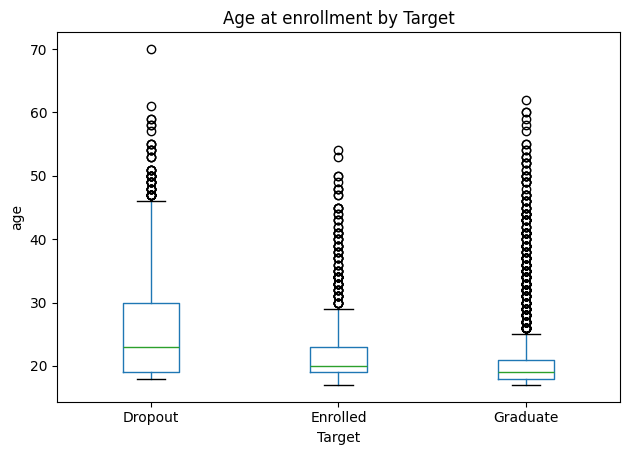

In [ ]:
# basic stats about age
print("age stats:")
print(df["Age at enrollment"].describe())
print()

# get the ages for each group separately
dropouts = df[df["Target"] == "Dropout"]
enrolled = df[df["Target"] == "Enrolled"]
graduates = df[df["Target"] == "Graduate"]

print("Dropout students - average age:", round(dropouts["Age at enrollment"].mean(), 1))
print("Enrolled students - average age:", round(enrolled["Age at enrollment"].mean(), 1))
print("Graduate students - average age:", round(graduates["Age at enrollment"].mean(), 1))

# make a boxplot to visualize it
df.boxplot(column="Age at enrollment", by="Target", grid=False)
plt.suptitle("")  # gets rid of the ugly automatic title
plt.title("Age at enrollment by Target")
plt.ylabel("age")
plt.tight_layout()
plt.show()


## Questions im trying to answer

1. do students with higher grades before college do better?
2. is there a difference between daytime and evening students dropping out?
3. do students with scholarships graduate more?


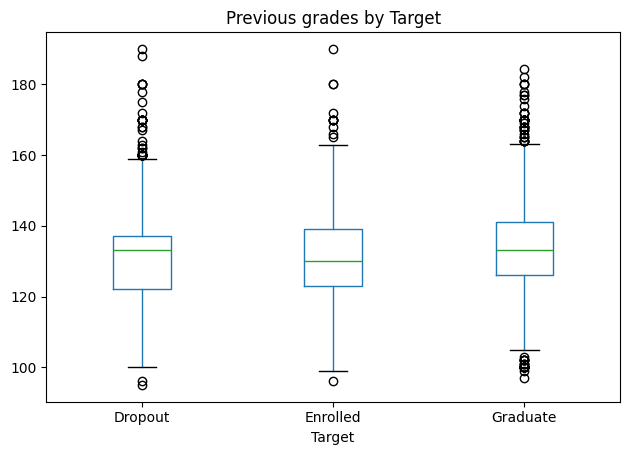

average previous grade for each group:
   Dropout -> 131.11
   Enrolled -> 131.21
   Graduate -> 134.08


In [ ]:
# question 1: do higher previous grades = better outcomes?

# make a boxplot
df.boxplot(column="Previous qualification (grade)", by="Target", grid=False)
plt.suptitle("")  # remove the auto title thing
plt.title("Previous grades by Target")
plt.tight_layout()
plt.show()

# print the average grade for each group
print("average previous grade for each group:")
groups = df.groupby("Target")
for name, group in groups:
    avg = round(group["Previous qualification (grade)"].mean(), 2)
    print("  ", name, "->", avg)


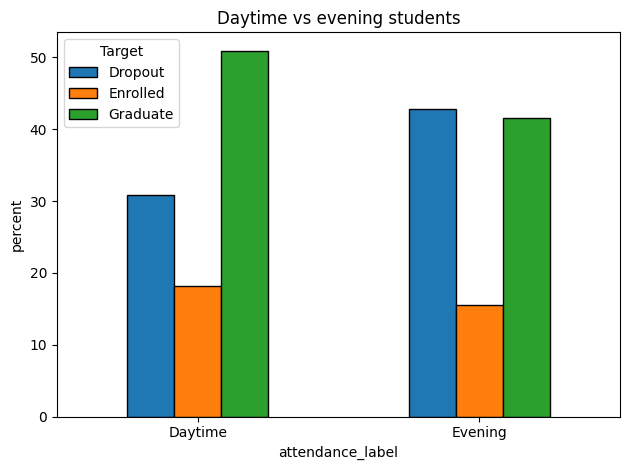

percentages:
Target            Dropout  Enrolled  Graduate
attendance_label                             
Daytime              30.8      18.2      51.0
Evening              42.9      15.5      41.6


In [ ]:
# question 2: daytime vs evening - who drops out more?

ct = pd.crosstab(df["attendance_label"], df["Target"], normalize="index") * 100
ct = ct[["Dropout", "Enrolled", "Graduate"]]

# bar chart
ct.plot(kind="bar", edgecolor="black")
plt.title("Daytime vs evening students")
plt.ylabel("percent")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("percentages:")
print(ct.round(1))


In [ ]:
# question 3: do scholarship students graduate more?

ct = pd.crosstab(df["scholarship_label"], df["Target"], normalize="index") * 100
result = ct[["Dropout", "Enrolled", "Graduate"]].round(1)

print("scholarship vs no scholarship:")
print(result)

# lets also just say the answer plainly
scholarship_grad = result.loc["Scholarship", "Graduate"]
no_scholarship_grad = result.loc["No scholarship", "Graduate"]
print()
print("scholarship students graduate rate:", scholarship_grad, "%")
print("no scholarship students graduate rate:", no_scholarship_grad, "%")

if scholarship_grad > no_scholarship_grad:
    print("so yeah scholarship students do graduate more!")
else:
    print("hmm actually scholarship students dont graduate more")


scholarship vs no scholarship:
Target             Dropout  Enrolled  Graduate
scholarship_label                             
No scholarship        38.7      20.0      41.3
Scholarship           12.2      11.8      76.0

scholarship students graduate rate: 76.0 %
no scholarship students graduate rate: 41.3 %
so yeah scholarship students do graduate more!
